# 09. Tokenization Latency, API Cost, and Context Window Budget Analysis

This notebook measures the practical operational and economic consequences of subword tokenization efficiency for **Twi** and **Ewe** text across general multilingual models (**mBERT**, **XLM-R**, **AfroXLMR**), regional models (**ABENA**), and **GhanaTok** (BPE and Unigram).

### Core Metrics Evaluated:
1. **Tokenization Speed / Latency**: Encoding throughput measured across 5 runs (with warm-up discard) in sentences/second and characters/second.
2. **API Cost Multipliers**: Price-independent ratios comparing how much more expensive it is to process identical text under multilingual baselines versus GhanaTok.
3. **Context Window Capacity Budgets**: Maximum usable words fitting into standard context windows (4k, 32k, 128k tokens).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure repo root is on sys.path
sys.path.insert(0, str(Path.cwd().parent))
from src.latency_benchmark import benchmark_latency

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## 1. Tokenization Latency Benchmark

In [2]:
latency_path = Path("../reports/tables/latency_benchmark.csv")
latency_df = pd.read_csv(latency_path)
latency_df

,tokenizer,language,n_sentences,total_chars,mean_seconds_per_run,std_seconds_per_run,sentences_per_second,chars_per_second
0,mBERT,twi,608,46125,0.3131,0.0339,1942.03,147329.35
1,XLM-R,twi,608,46125,0.3055,0.0513,1990.20,150983.84
2,AfroXLMR,twi,608,46125,0.1808,0.0036,3362.38,255081.95
3,ABENA,twi,608,46125,0.1972,0.0060,3082.70,233864.02
4,GhanaTok,twi,608,46125,0.2916,0.1478,2085.34,158201.07
5,GhanaTok-Unigram,twi,608,46125,0.0231,0.0043,26363.49,2000026.02
6,mBERT,ewe,347,37395,0.1270,0.0091,2731.69,294384.43
7,XLM-R,ewe,347,37395,0.1319,0.0051,2631.67,283606.30
8,AfroXLMR,ewe,347,37395,0.1297,0.0028,2675.72,288352.90
9,GhanaTok,ewe,347,37395,0.1037,0.0052,3344.90,360468.41


## 2. Cost Estimates & Price-Independent Multipliers

In [3]:
multiplier_path = Path("../reports/tables/cost_multiplier.csv")
multiplier_df = pd.read_csv(multiplier_path)
multiplier_df

,language,tokenizer,mean_fertility,multiplier_vs_cheapest_unigram,multiplier_vs_ghanatok_bpe
0,ewe,GhanaTok-Unigram,1.349,1.000,0.771
1,ewe,GhanaTok,1.750,1.297,1.000
2,ewe,mBERT,2.291,1.698,1.309
3,ewe,AfroXLMR,2.608,1.933,1.490
4,ewe,XLM-R,2.608,1.933,1.490
5,twi,GhanaTok-Unigram,1.251,1.000,0.755
6,twi,GhanaTok,1.656,1.324,1.000
7,twi,mBERT,2.389,1.910,1.443
8,twi,ABENA,2.419,1.934,1.461
9,twi,AfroXLMR,2.444,1.954,1.476


## 3. Context Window Capacity Budgets (4k, 32k, 128k tokens)

In [4]:
budget_path = Path("../reports/tables/context_budget.csv")
budget_df = pd.read_csv(budget_path)
budget_df

,language,tokenizer,mean_fertility,max_words_in_4k_window,max_words_in_32k_window,max_words_in_128k_window
0,ewe,GhanaTok-Unigram,1.349,2965,23721,94885
1,ewe,GhanaTok,1.750,2286,18286,73143
2,ewe,mBERT,2.291,1746,13968,55871
3,ewe,AfroXLMR,2.608,1534,12270,49080
4,ewe,XLM-R,2.608,1534,12270,49080
5,twi,GhanaTok-Unigram,1.251,3197,25580,102318
6,twi,GhanaTok,1.656,2415,19324,77295
7,twi,mBERT,2.389,1674,13395,53579
8,twi,ABENA,2.419,1654,13229,52914
9,twi,AfroXLMR,2.444,1637,13093,52373


## 4. Visualizing Cost Multipliers & Context Capacity

<cell_9_expr>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


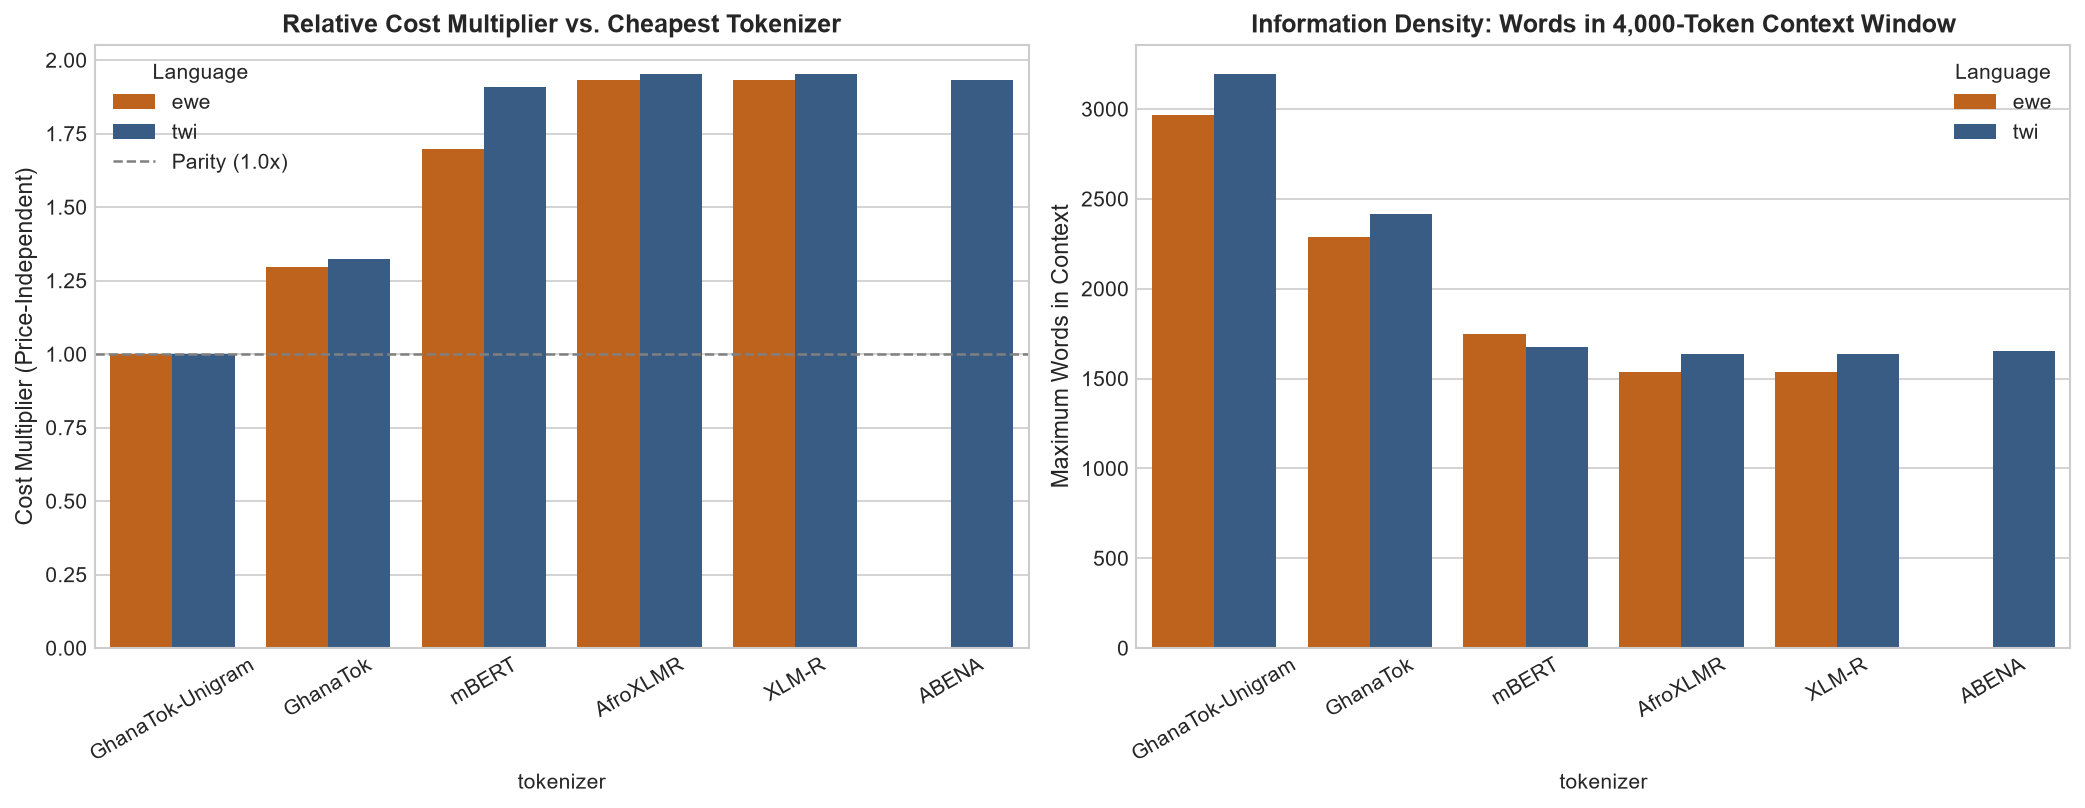

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
palette = {"twi": "#2b5c8f", "ewe": "#d95f02"}

# Panel 1: Cost Multiplier
sns.barplot(data=multiplier_df, x="tokenizer", y="multiplier_vs_cheapest_unigram", hue="language", palette=palette, ax=axes[0])
axes[0].set_title("Relative Cost Multiplier vs. Cheapest Tokenizer", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Cost Multiplier (Price-Independent)", fontsize=11)
axes[0].axhline(1.0, color="gray", linestyle="--", linewidth=1.2, label="Parity (1.0x)")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="Language")

# Panel 2: Context Window Budget
sns.barplot(data=budget_df, x="tokenizer", y="max_words_in_4k_window", hue="language", palette=palette, ax=axes[1])
axes[1].set_title("Information Density: Words in 4,000-Token Context Window", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Maximum Words in Context", fontsize=11)
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(title="Language")

plt.tight_layout()
plt.show()